In [1]:
import pyranges as pr
import os
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix, csr_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random

import networkx as nx

import community as community_louvain

from icecream import ic

from collections import OrderedDict

import matplotlib.pyplot as plt
%matplotlib inline
import umap.umap_ as umap
reducer = umap.UMAP()

import sklearn.decomposition as skd

import traceback

In [4]:
# ROOT_PATH = '/Users/joachimwolff/data/epigenetic_graph_analyzer/'
ROOT_PATH = '/home/joachim/data/MHH/epigenetic_graph_analyzer/'

path_interactions_E12_5_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.txt.gz"
path_interactions_E12_5_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.txt.gz"

path_interactions_E14_5_rep1 = ROOT_PATH + "phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.txt.gz"
path_interactions_E14_5_rep2 = ROOT_PATH + "phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.txt.gz"

path_output_bedpe_E12_5_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E12_5_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.bedpe"

path_output_bedpe_E14_5_rep1 = ROOT_PATH + "phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E14_5_rep2 = ROOT_PATH + "phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.bedpe"

path_output_cool_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.cool"
path_output_cool_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.cool"

path_output_cool_merged = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_merged.cool"


path_mm10_chromosome_size = ROOT_PATH + "mm10.chrom.sizes.sort"
path_promoter = ROOT_PATH + "mm10_promoter.bed"


# histones
path_histones_H3K3me2_E12_5_rep1 = ROOT_PATH + "histones/GSM6505186_H3K4me2_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_E12_5_rep2 = ROOT_PATH + "histones/GSM6505187_H3K4me2_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K3me2_E14_5_rep1 = ROOT_PATH + "histones/GSM6505192_H3K4me2_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_E14_5_rep2 = ROOT_PATH + "histones/GSM6505193_H3K4me2_Pinna_E14.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_E12_5_rep1  = ROOT_PATH + "histones/GSM6505188_H3K27me3_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_E12_5_rep2  = ROOT_PATH + "histones/GSM6505189_H3K27me3_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_E14_5_rep1  = ROOT_PATH + "histones/GSM6505194_H3K27me3_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_E14_5_rep2  = ROOT_PATH + "histones/GSM6505195_H3K27me3_Pinna_E14.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_E12_5_rep1  = ROOT_PATH + "histones/GSM6505184_H3K27ac_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_E12_5_rep2  = ROOT_PATH + "histones/GSM6505185_H3K27ac_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_E14_5_rep1  = ROOT_PATH + "histones/GSM6505190_H3K27ac_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_E14_5_rep2  = ROOT_PATH + "histones/GSM6505191_H3K27ac_Pinna_E14.5_WT_rep2.scaled_0100.bw"


# RNA
path_RNA_E12_5_rep1 = ROOT_PATH + "RNA/GSM6505221_RNAseq_E12.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_E12_5_rep2 = ROOT_PATH + "RNA/GSM6505222_RNAseq_E12.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_E12_5_rep3 = ROOT_PATH + "RNA/GSM6505223_RNAseq_E12.5-Pinna_TruSeq_3_cpm_100.bw"

path_RNA_E14_5_rep1 = ROOT_PATH + "RNA/GSM6505224_RNAseq_E14.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_E14_5_rep2 = ROOT_PATH + "RNA/GSM6505225_RNAseq_E14.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_E14_5_rep3 = ROOT_PATH + "RNA/GSM6505226_RNAseq_E14.5-Pinna_TruSeq_3_cpm_100.bw"

# ATAC
path_ATAC_E12_5_rep1 = ROOT_PATH + "ATAC/GSM6505176_ATAC_WT_E12.5_Pinna_SK_1.scaled_0100.bw"
path_ATAC_E12_5_rep2 = ROOT_PATH + "ATAC/GSM6505177_ATAC_WT_E12.5_Pinna_SK_2.scaled_0100.bw"
path_ATAC_E12_5_rep3 = ROOT_PATH + "ATAC/GSM6505178_ATAC_WT_E12.5_Pinna_SK_3.scaled_0100.bw"

path_ATAC_E14_5_rep1 = ROOT_PATH + "ATAC/GSM6505179_ATAC_E14.5_WT_Pinna_SK_1.scaled_0100.bw"
path_ATAC_E14_5_rep2 = ROOT_PATH + "ATAC/GSM6505180_ATAC_E14.5_WT_Pinna_SK_2.scaled_0100.bw"
path_ATAC_E14_5_rep3 = ROOT_PATH + "ATAC/GSM6505181_ATAC_E14.5_WT_Pinna_SK_3.scaled_0100.bw"



In [5]:
def washU_to_bedpe(path_input, path_output):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression='gzip')
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [45]:
washU_to_bedpe(path_interactions_E12_5_rep1, path_output_bedpe_E12_5_rep1)
# washU_to_bedpe(path_interactions_E12_5_rep2, path_output_bedpe_E12_5_rep2)
washU_to_bedpe(path_interactions_E14_5_rep1, path_output_bedpe_E14_5_rep1)
# washU_to_bedpe(path_interactions_E14_5_rep2, path_output_bedpe_E14_5_rep2)

In [72]:
def createMatrix(pd_interactions, cut_intervals, allow_inter_chr_interactions):
    hic_matrix_csr = dok_matrix((len(cut_intervals), len(cut_intervals)))

    hic_matrix = hm.hiCMatrix()
    hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
    for row in pd_interactions.iterrows():
        
        chromosome_1 = str(row[1][0])
        start_1 = int(row[1][1]) + 1
        end_1 = int(row[1][2]) - 1

        chromosome_2 = str(row[1][3])
        start_2 = int(row[1][4]) + 1
        end_2 = int(row[1][5]) - 1

        value = float(row[1][6])

        if not allow_inter_chr_interactions:
            if chromosome_1 != chromosome_2:
                continue
        
        try:
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
            hic_matrix.matrix[bin_id_1, bin_id_2] = value

        except Exception as exp:
            print(traceback.print_exc())
            ic(chromosome_1, start_1, end_1)
            ic(chromosome_2, start_2, end_2)
            break
            # continue
        
        
    hic_matrix.matrix = hic_matrix.matrix.tocsr()
    return hic_matrix

In [89]:

def importInteractionsFromWashU(list_of_washU_files, chromosome_size_file, resolution, allow_inter_chr_interactions=False):
    
    hic_matrix_list = []
    pd_interactions_list = []
    matrix_merged_csr = None

    chrom_sizes = OrderedDict()
    size_genome = 0
    with open(chromosome_size_file, 'r') as file:
        file_ = True
        while file_:
            file_ = file.readline().strip()
            if file_ != '':
                line_split = file_.split('\t')
                chrom_sizes[line_split[0]] = int(line_split[1])
                size_genome += int(line_split[1])
    # chrom_sizes = list(chrom_sizes.items())

    cut_intervals = []
    if isinstance(resolution, int):
        for chromosome in chrom_sizes:
            for interval in range(0, chromosome[1], resolution):
                cut_intervals.append(tuple([chromosome[0], interval,
                                            min(chromosome[1], interval + resolution), 1.0]))
    else:
        restriction_cut_sites = pd.read_table(resolution, sep='\t')
        # restriction_cut_sites.columns = ['Chromosome', 'Start', 'End', '.', 'x', 'Strand']
        for row in restriction_cut_sites.iterrows():
            if row[1]['Chromosome'] in chrom_sizes:
                cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))

    for i, path_interactions in enumerate(list_of_washU_files):
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression='gzip')
        
        pr_interactions_list.append(pd_interactions)
        hic_matrix = createMatrix(pd_interactions, cut_intervals, allow_inter_chr_interactions)
        
        
        hic_matrix_list.append(hic_matrix)

        # merge matrices
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
    
    

    # compute an intersection matrix
    if len(hic_matrix_list) > 1:
        intersection_result_matrix = hic_matrix_list[0]
        for hic_matrix in hic_matrix_list[1:]:
            intersection_matrix = intersection_result_matrix.matrix.multiply(hic_matrix.matrix).tocsr()
            intersection_matrix.eliminate_zeros()
            non_zero_ids = intersection_matrix.nonzero()
            data_merged_matrix = np.asarray(intersection_result_matrix.matrix[non_zero_ids]).flatten()
            data_hic_matrix = np.asarray(hic_matrix.matrix[non_zero_ids]).flatten()
            data_intersection = data_merged_matrix + data_hic_matrix
            intersection_result_matrix = csr_matrix((data_intersection, non_zero_ids),shape=intersection_result_matrix.matrix.shape)

    hic_matrix_list.append(matrix_merged_csr)
    hic_matrix_list.append(intersection_result_matrix / len(list_of_washU_files))

    return hic_matrix_list

In [ ]:
# chr6	52164817	52164877	Hoxa2_1

In [90]:
interaction_matrices_sample_Pinna_12_5 = importInteractionsFromWashU([path_interactions_E12_5_rep1, path_interactions_E12_5_rep2], path_mm10_chromosome_size, resolution=os.path.join(ROOT_PATH, 'hicup_digest/mm10_hindIII.txt'))
interaction_matrices_sample_Pinna_14_5 = importInteractionsFromWashU([path_interactions_E14_5_rep1, path_interactions_E14_5_rep2], path_mm10_chromosome_size, resolution=os.path.join(ROOT_PATH, 'hicup_digest/mm10_hindIII.txt'))


In [91]:
interaction_matrices_sample_Pinna_14_5[0].matrix[617308, :]

<1x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 23 stored elements in Compressed Sparse Row format>

In [92]:
interaction_matrices_sample_Pinna_14_5[1].matrix[617308, :]

<1x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 31 stored elements in Compressed Sparse Row format>

In [93]:
interaction_matrices_sample_Pinna_14_5[2][617308, :]


<1x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 33 stored elements in Compressed Sparse Row format>

In [94]:
interaction_matrices_sample_Pinna_14_5[3]


<851636x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 72051 stored elements in Compressed Sparse Row format>

In [95]:
interaction_matrices_sample_Pinna_12_5[3]


<851636x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 57483 stored elements in Compressed Sparse Row format>

In [96]:
ic(interaction_matrices_sample_Pinna_14_5)

ic| interaction_matrices_sample_Pinna_14_5: [<hicmatrix.HiCMatrix.hiCMatrix object at 0x7f6ac52a0fa0>,
                                             <851636x851636 sparse matrix of type '<class 'numpy.float64'>'
                                            	with 255586 stored elements in Compressed Sparse Row format>,
                                             <851636x851636 sparse matrix of type '<class 'numpy.float64'>'
                                            	with 72051 stored elements in Compressed Sparse Row format>]


 <851636x851636 sparse matrix of type '<class 'numpy.float64'>'
 	with 255586 stored elements in Compressed Sparse Row format>,
 <851636x851636 sparse matrix of type '<class 'numpy.float64'>'
 	with 72051 stored elements in Compressed Sparse Row format>]

In [97]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        
        view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1], bait_location[1])
        if view_point_start is None:
            
            view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1]+1, bait_location[1]+1)
            
            if view_point_start is None:
                print(traceback.print_exc())
                ic(bait_location, row)
                break
        matrix_list.append(chic_matrix[3][view_point_start[0], :])
        bait_list.append(row[['Name']])

    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    return sample_matrix, bait_list

In [127]:
sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_12_5)
sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_14_5)

ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Trace

In [130]:
sample_matrix_Pinna_E12_5

<25111x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 57912 stored elements in Compressed Sparse Row format>

In [13]:
bait_list_Pinna_E14_5_df = pd.DataFrame(bait_list_Pinna_E14_5, columns=['Name'])
bait_list_Pinna_E14_5_df[bait_list_Pinna_E14_5_df["Name"] == "Hoxa2_1"]


,Name
8767,Hoxa2_1


In [14]:
promoters = pr.read_bed(path_promoter)

In [15]:
promoters.df[promoters.df['Name'] == 'Tax1bp1_2']

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
8147,chr6,52713984,52714044,Tax1bp1_2,900,+,52714033,52714044


In [100]:
def createGraphAndFindCommunities(sample_matrix, bait_list, path_output_graphml):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if bait == 8767:
            ic(bait, OE, sample_matrix.data[i])
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"


    for bait in bait_ids:
        G.nodes[bait]['name'] = bait_list[bait][0]
        G.nodes[bait]['colorType'] = "green"

    # partition = community_louvain.best_partition(G)
    partition_list = nx.community.louvain_communities(G, seed=42)

    for partition_id, partition in enumerate(partition_list):
        for node in partition:
            G.nodes[node]['partition'] = partition_id
            G.nodes[node]['partition_color'] = partition_id



    nx.write_graphml(G, path_output_graphml)

    return G, partition_list

In [101]:
G_Pinna_E12_5, partition_Pinna_E12_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5, ROOT_PATH + "Pinna_E12_5.graphml")
G_Pinna_E14_5, partition_Pinna_E14_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5, ROOT_PATH + "Pinna_E14_5.graphml")

ic| bait: 8767, OE: 616802, sample_matrix.data[i]: 6.71
ic| bait: 8767, OE: 616803, sample_matrix.data[i]: 8.895
ic| bait: 8767, OE: 616804, sample_matrix.data[i]: 9.625
ic| bait: 8767, OE: 616815, sample_matrix.data[i]: 9.844999999999999
ic| bait: 8767, OE: 616846, sample_matrix.data[i]: 7.3100000000000005
ic| bait: 8767, OE: 616847, sample_matrix.data[i]: 7.91
ic| bait: 8767, OE: 616849, sample_matrix.data[i]: 26.655
ic| bait: 8767, OE: 616850, sample_matrix.data[i]: 25.955
ic| bait: 8767, OE: 616851, sample_matrix.data[i]: 16.09
ic| bait: 8767, OE: 616852, sample_matrix.data[i]: 16.785
ic| bait: 8767, OE: 616891, sample_matrix.data[i]: 15.28
ic| bait: 8767, OE: 616892, sample_matrix.data[i]: 22.115000000000002
ic| bait: 8767, OE: 616893, sample_matrix.data[i]: 14.24
ic| bait: 8767, OE: 616897, sample_matrix.data[i]: 9.385
ic| bait: 8767, OE: 616902, sample_matrix.data[i]: 9.28
ic| bait: 8767, OE: 616904, sample_matrix.data[i]: 7.46
ic| bait: 8767, OE: 616906, sample_matrix.data[i]: 

In [102]:
partition_Pinna_E12_5

[{6, 26463, 26464},
 {11,
  802,
  26338,
  26593,
  26594,
  26595,
  26596,
  26597,
  26659,
  26660,
  26661,
  26662,
  26703,
  26709,
  26710,
  26712,
  26713,
  26714,
  26715},
 {18, 805, 808, 809, 810, 27483, 27487, 27494, 27495, 27497, 27538},
 {21, 27850},
 {27, 824, 29789, 29837, 29838, 29839},
 {30, 30207, 30209},
 {31, 30067, 30071, 30074, 30076, 30081},
 {34,
  35,
  30945,
  30946,
  30947,
  31060,
  31061,
  31114,
  31117,
  31118,
  31119,
  31131,
  31134,
  31135,
  31136,
  31137,
  31138},
 {42,
  31298,
  31300,
  31301,
  31315,
  31316,
  31317,
  31318,
  31319,
  31320,
  31321,
  31322},
 {51, 31789},
 {52,
  53,
  845,
  847,
  32016,
  32045,
  32063,
  32231,
  32232,
  32342,
  32350,
  32351,
  32371,
  32375,
  32376,
  32377,
  32378,
  32379},
 {55, 56, 32838},
 {61, 860, 35656},
 {67, 68, 72, 866, 867, 868, 35734, 35735, 35736, 35737, 35738, 35739, 35740},
 {76, 36218},
 {81, 36385},
 {89, 36530, 36555},
 {90, 36723},
 {91, 92, 886, 892, 36636},

In [103]:
G_Pinna_E12_5.nodes[8767]['partition']

1284

In [104]:
G_Pinna_E14_5.nodes[8767]['partition']

1282

In [14]:
partition_Pinna_E12_5[8767]

1353

In [15]:
partition_Pinna_E14_5[8767]

1342

In [19]:
for bait in bait_list_Pinna_E12_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [20]:
for bait in bait_list_Pinna_E14_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [11]:
def createDataMatrixFromBigWig(sample_matrix, interaction_matrix, path_bigwig_list):
    list_of_data_matrices = []
    sample, interaction = sample_matrix.nonzero()

    for file_path in path_bigwig_list:
        # Open the bigwig file
        bw = pyBigWig.open(file_path)

        data_matrix = dok_matrix(sample_matrix.shape)
        for sample_bin, interaction_bin in zip(sample, interaction):
            chromosome, start, end , _ = interaction_matrix.getBinPos(interaction_bin)
            
            # Read the data from the bigwig file
            value = bw.stats(chromosome, start, end)
            data_matrix[sample_bin, interaction_bin] = value[0]
        
        list_of_data_matrices.append(data_matrix.tocsr())
    return list_of_data_matrices

In [12]:
bigwig_files_Pinna_E12_5 = [path_histones_H3K27ac_E12_5_rep1, path_histones_H3K27ac_E12_5_rep2,  path_histones_H3K27me3_E12_5_rep1, path_histones_H3K27me3_E12_5_rep2,path_histones_H3K3me2_E12_5_rep1, path_histones_H3K3me2_E12_5_rep2,  path_RNA_E12_5_rep1, path_RNA_E12_5_rep2, path_RNA_E12_5_rep3,  path_ATAC_E12_5_rep1, path_ATAC_E12_5_rep2, path_ATAC_E12_5_rep3]
bigwig_files_Pinna_E14_5 = [path_histones_H3K27ac_E14_5_rep1, path_histones_H3K27ac_E14_5_rep2, path_histones_H3K27me3_E14_5_rep1, path_histones_H3K27me3_E14_5_rep2, path_histones_H3K3me2_E14_5_rep1, path_histones_H3K3me2_E14_5_rep2,path_RNA_E14_5_rep1, path_RNA_E14_5_rep2, path_RNA_E14_5_rep3, path_ATAC_E14_5_rep1, path_ATAC_E14_5_rep2, path_ATAC_E14_5_rep3]
data_matrix_list_Pinna_E12_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E12_5, interaction_matrices_sample_Pinna_12_5[0], bigwig_files_Pinna_E12_5)
data_matrix_list_Pinna_E14_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E14_5, interaction_matrices_sample_Pinna_14_5[0], bigwig_files_Pinna_E14_5)

In [13]:
def createCommunityMatrix(sample_matrix, list_of_data_matrices, partition):
    matrix_list = [sample_matrix.tocsr(), *list_of_data_matrices]
    # Create matrix per community
    community_matrix_mean = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_median = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_sum = np.zeros((max(partition.values())+1, len(matrix_list)))

    elements_per_community = np.zeros(max(partition.values())+1)

    baits_partition_dict = {key: value for key, value in partition.items() if key < sample_matrix.shape[0]}
    for community_id in baits_partition_dict:
        for i, matrix in enumerate(matrix_list):
            try:
                community_matrix_mean[baits_partition_dict[community_id], i] += np.nan_to_num(np.mean(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_median[baits_partition_dict[community_id], i] += np.nan_to_num(np.median(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_sum[baits_partition_dict[community_id], i] += np.nan_to_num(np.sum(np.nan_to_num(matrix[community_id, :].data)))
            except (IndexError, KeyError):
                ic(i)
                ic(community_id)
        elements_per_community[baits_partition_dict[community_id]] += 1

    community_matrix_mean_normalized = community_matrix_mean / elements_per_community[:, np.newaxis]
    community_matrix_median_normalized = community_matrix_median / elements_per_community[:, np.newaxis]
    community_matrix_sum_normalized = community_matrix_sum / elements_per_community[:, np.newaxis]

    scaler = MinMaxScaler()
    community_matrix_mean = scaler.fit_transform(community_matrix_mean[np.any(community_matrix_mean != 0, axis=1)])
    community_matrix_median = scaler.fit_transform(community_matrix_median[np.any(community_matrix_median != 0, axis=1)])
    community_matrix_sum = scaler.fit_transform(community_matrix_sum[np.any(community_matrix_sum != 0, axis=1)])
    community_matrix_mean_normalized = scaler.fit_transform(community_matrix_mean_normalized[np.any(community_matrix_mean_normalized != 0, axis=1)])
    community_matrix_median_normalized = scaler.fit_transform(community_matrix_median_normalized[np.any(community_matrix_median_normalized != 0, axis=1)])
    community_matrix_sum_normalized = scaler.fit_transform(community_matrix_sum_normalized[np.any(community_matrix_sum_normalized != 0, axis=1)])

    return community_matrix_mean, community_matrix_median, community_matrix_sum, community_matrix_mean_normalized, community_matrix_median_normalized, community_matrix_sum_normalized


In [14]:
different_communities_Pinna_E_12_5 = createCommunityMatrix(sample_matrix_Pinna_E12_5, data_matrix_list_Pinna_E12_5, partition_Pinna_E12_5)
different_communities_Pinna_E_14_5 = createCommunityMatrix(sample_matrix_Pinna_E14_5, data_matrix_list_Pinna_E14_5, partition_Pinna_E14_5) 


In [28]:
len(different_communities_Pinna_E_12_5)

6

In [29]:
len(different_communities_Pinna_E_14_5)

6

In [15]:
def plotPCA(matrix, type_of_matrix):
    pca1, pca2 = skd.PCA(n_components=2).fit_transform(matrix).T
    title = "Scatter Plot PCA"
    # list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
    list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
    # list_of_colorings = community_matrix_median.T.tolist()

    list_of_colorings = matrix.T[[0,1,3,5,7,10]].tolist()

    plotEmbedding([pca1, pca2], list_of_titles, list_of_colorings, type_of_matrix + " " + title)



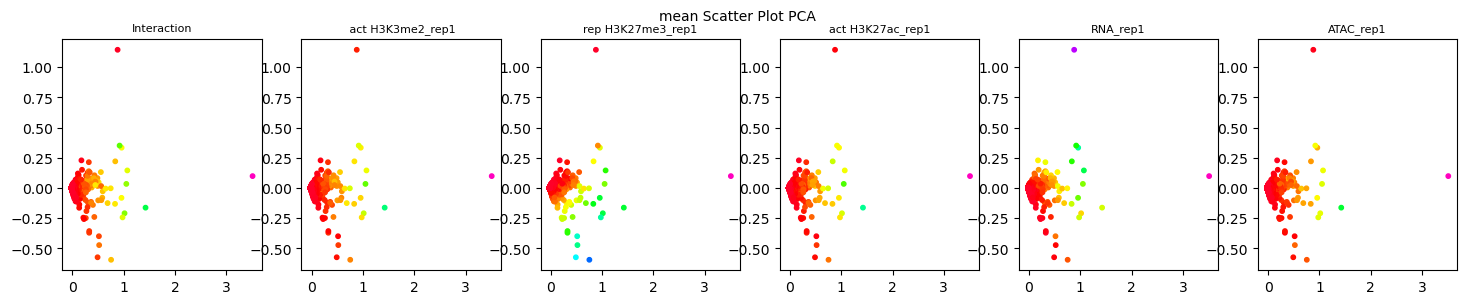

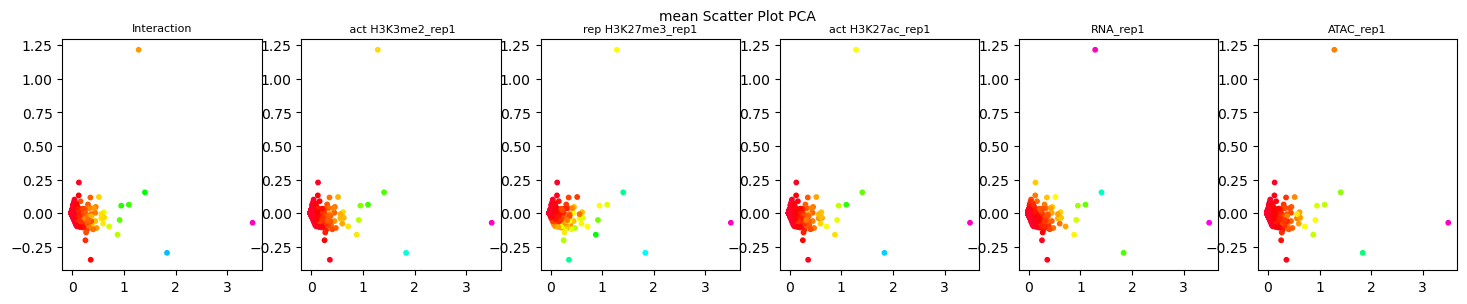

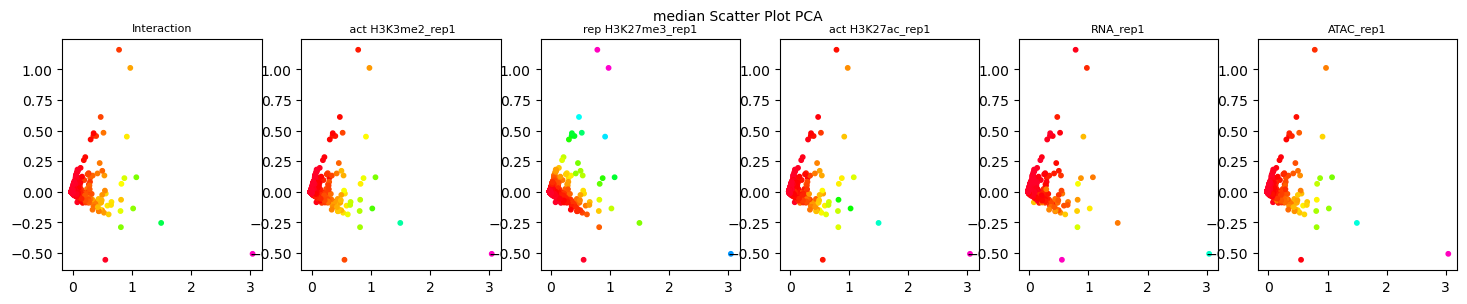

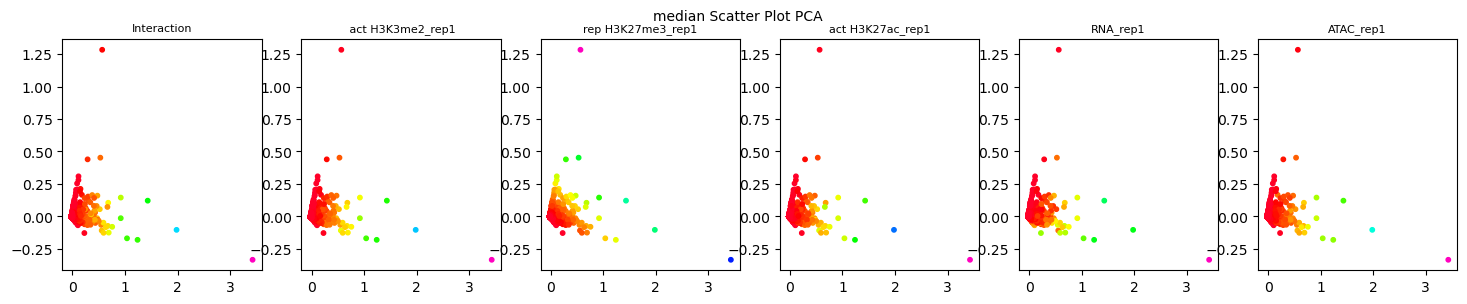

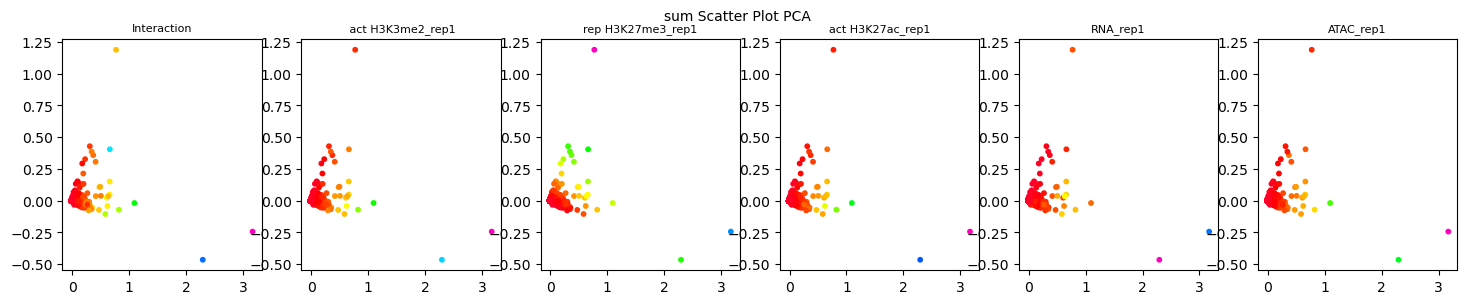

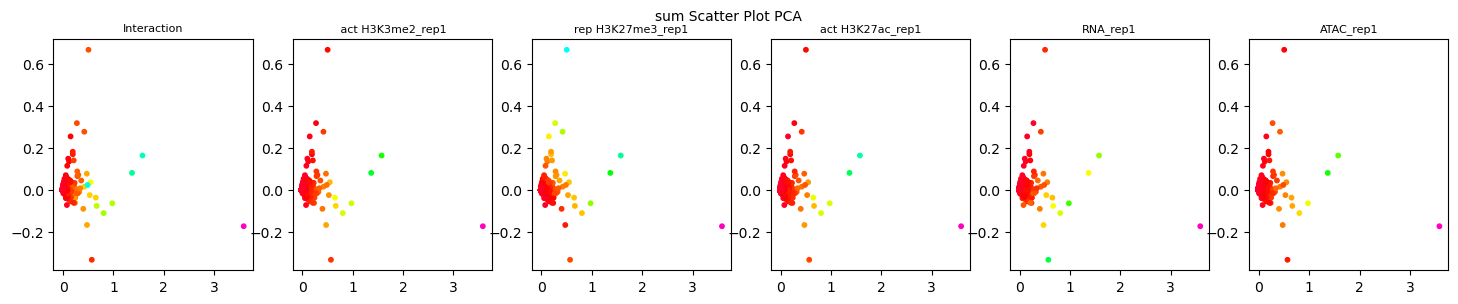

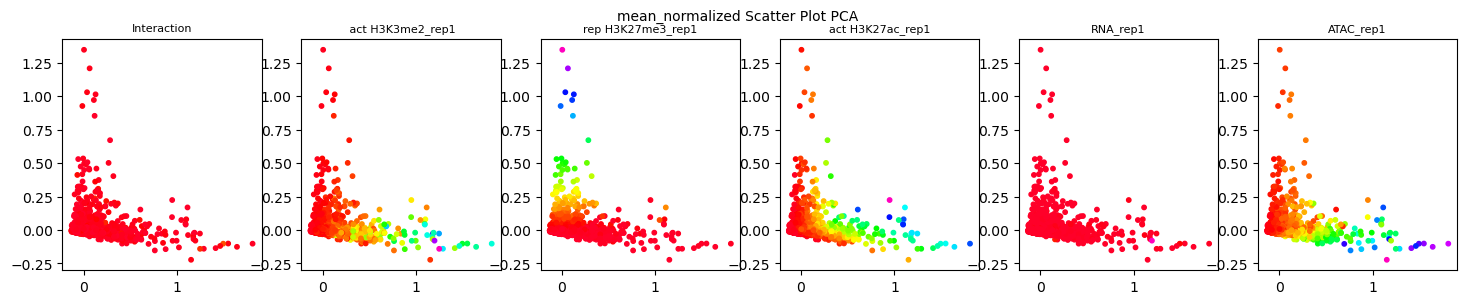

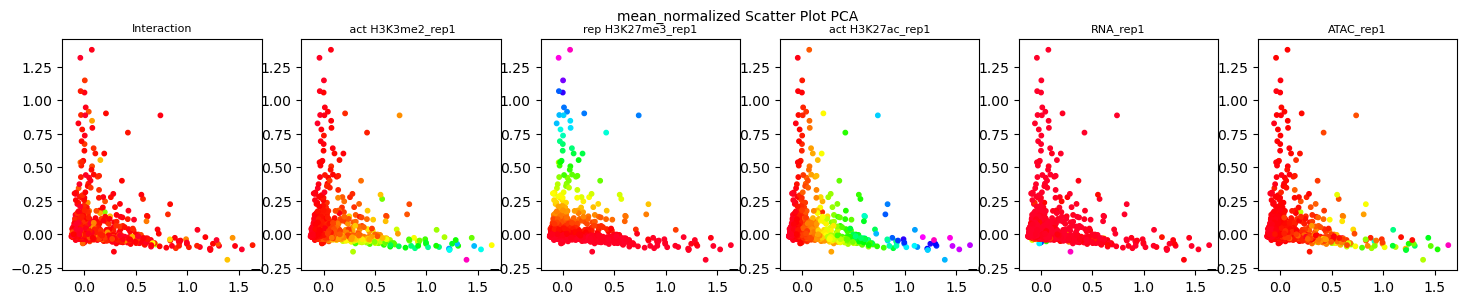

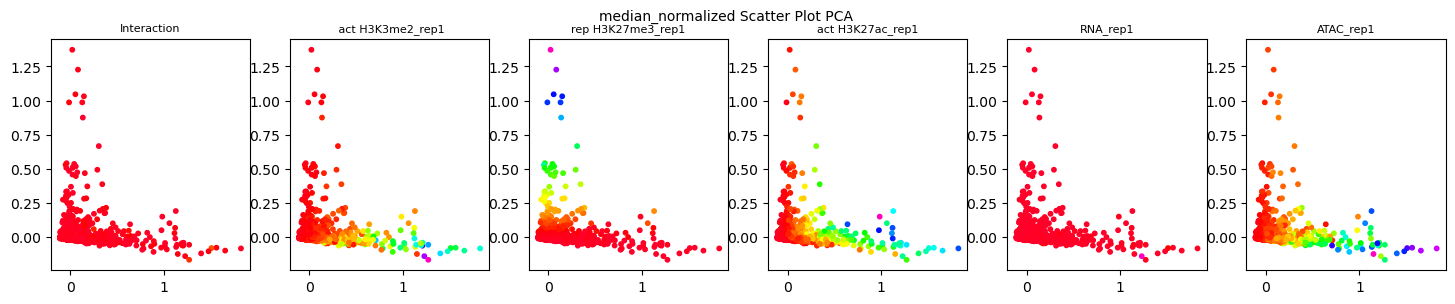

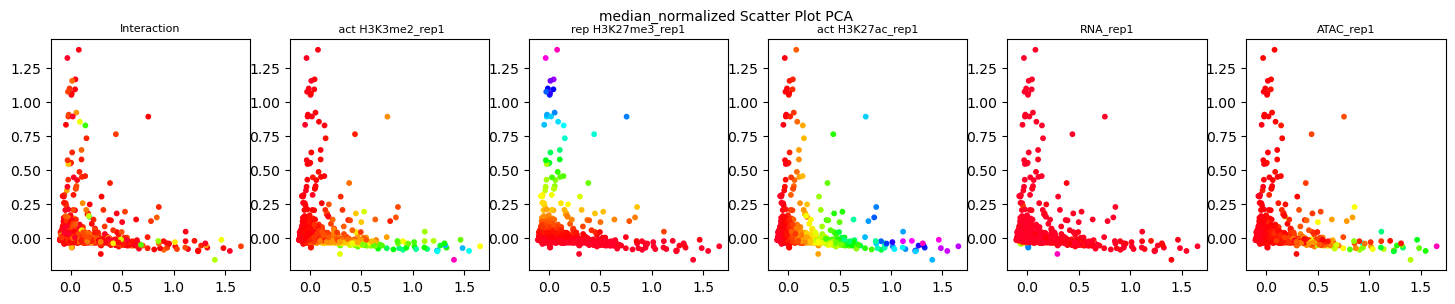

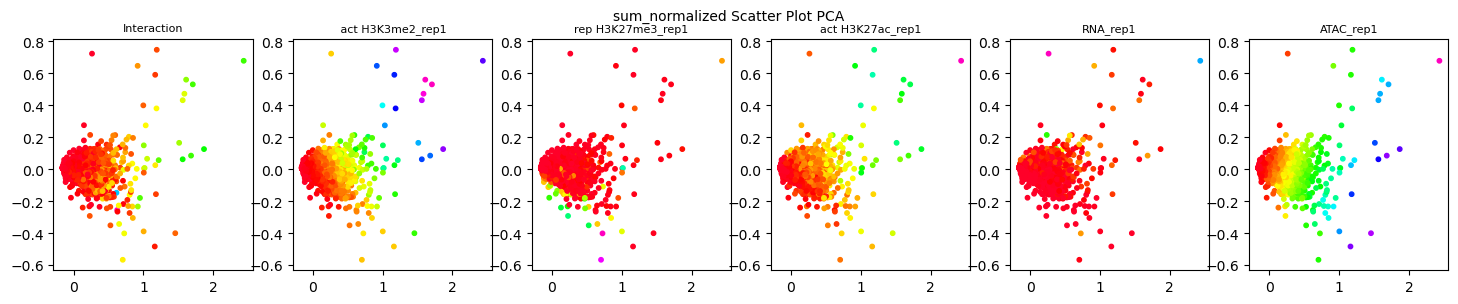

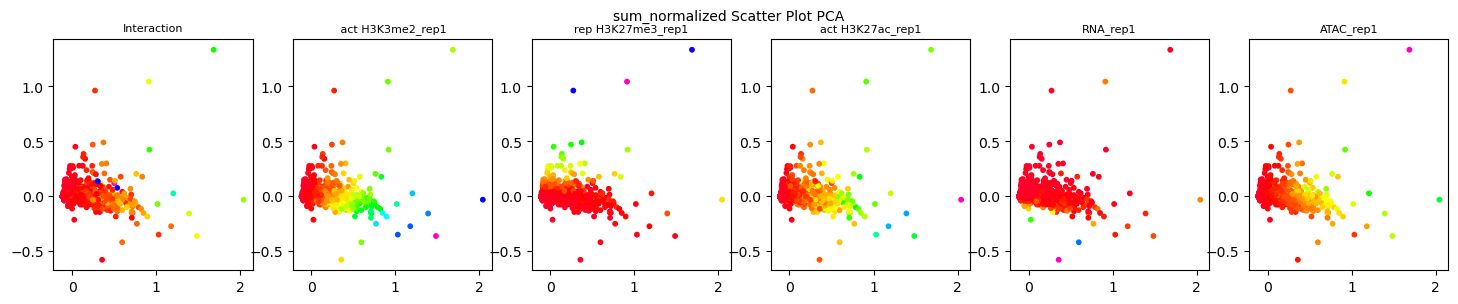

In [26]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotPCA(different_communities_Pinna_E_12_5[i], title)
    plotPCA(different_communities_Pinna_E_14_5[i], title)


In [16]:
def plotUMAP(matrix, type_of_matrix):
    embedding = reducer.fit_transform(matrix)
    title = "Scatter Plot PCA"
    # list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
    list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
    # list_of_colorings = community_matrix_median.T.tolist()

    list_of_colorings = matrix.T[[0,1,3,5,7,10]].tolist()

    plotEmbedding([embedding[:, 0], embedding[:, 1]], list_of_titles, list_of_colorings, type_of_matrix + " " + title)

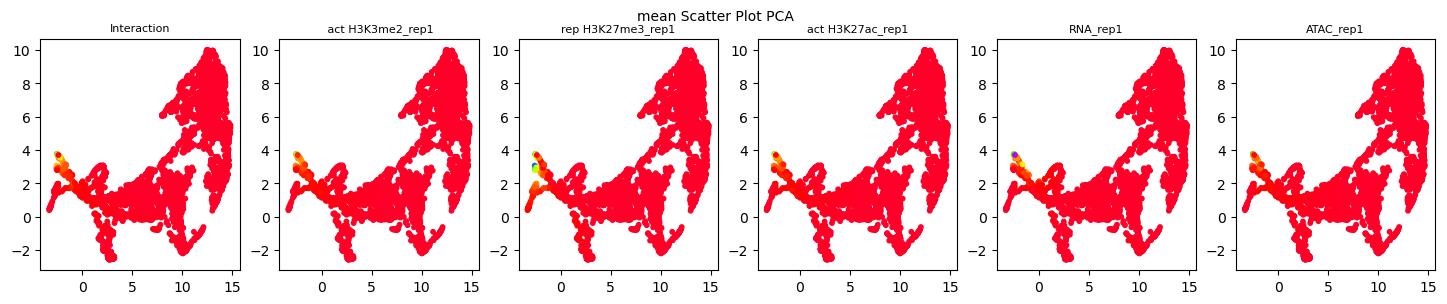

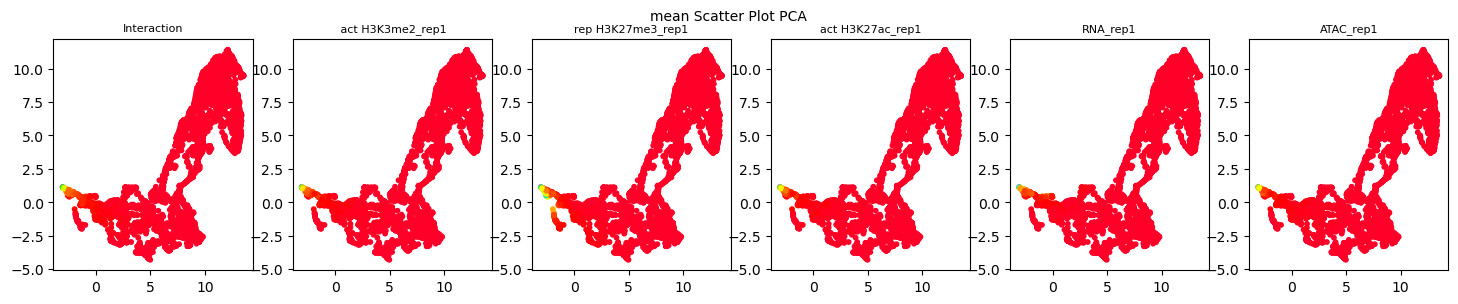

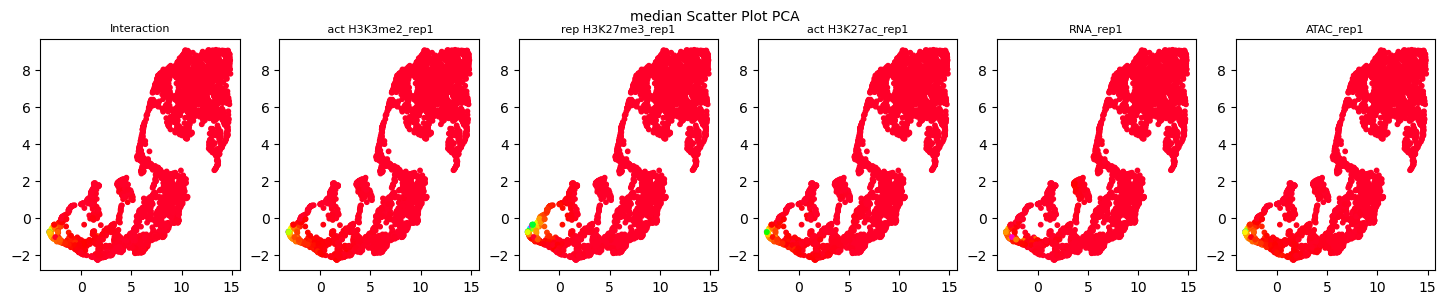

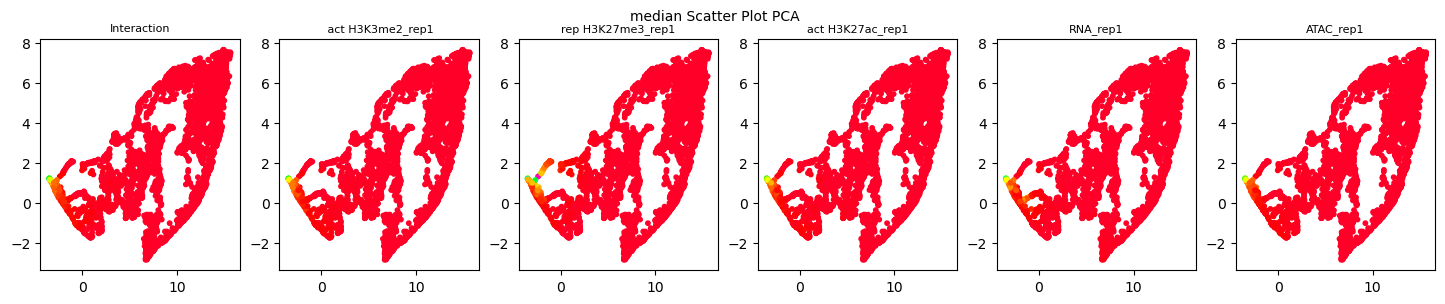

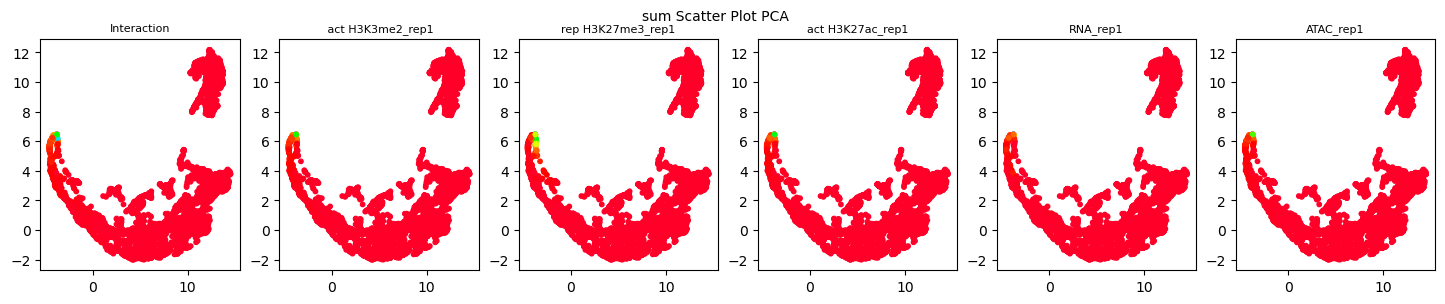

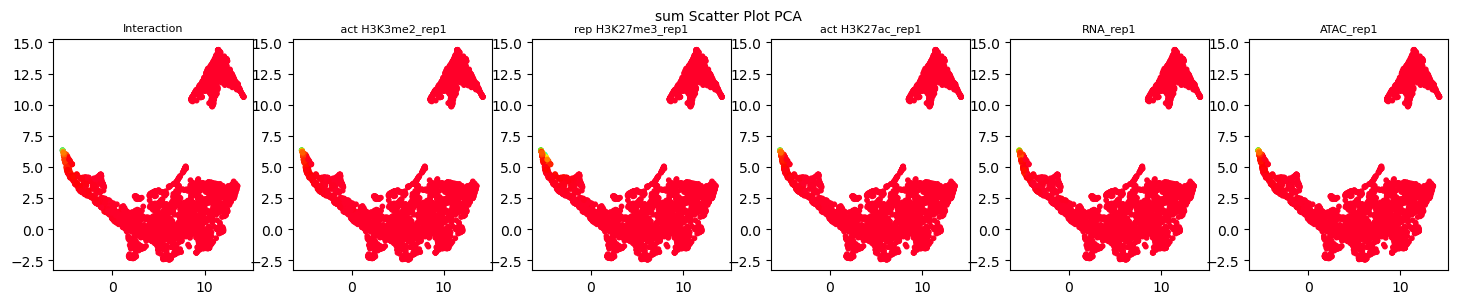

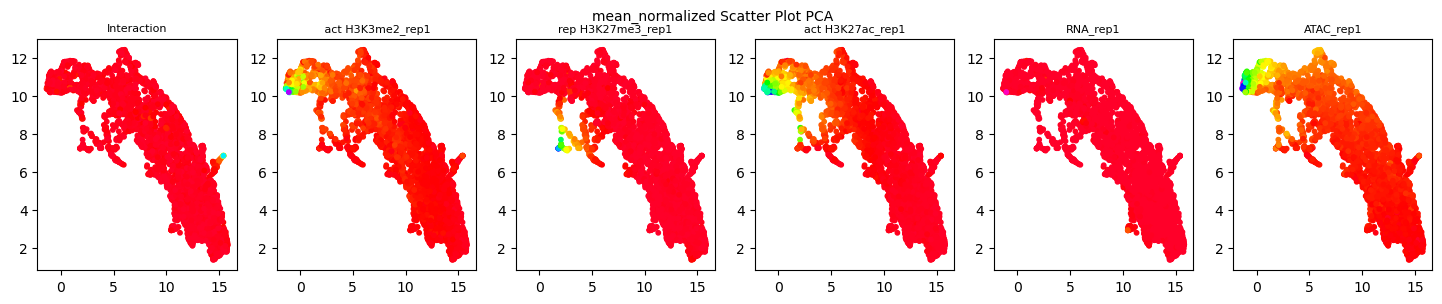

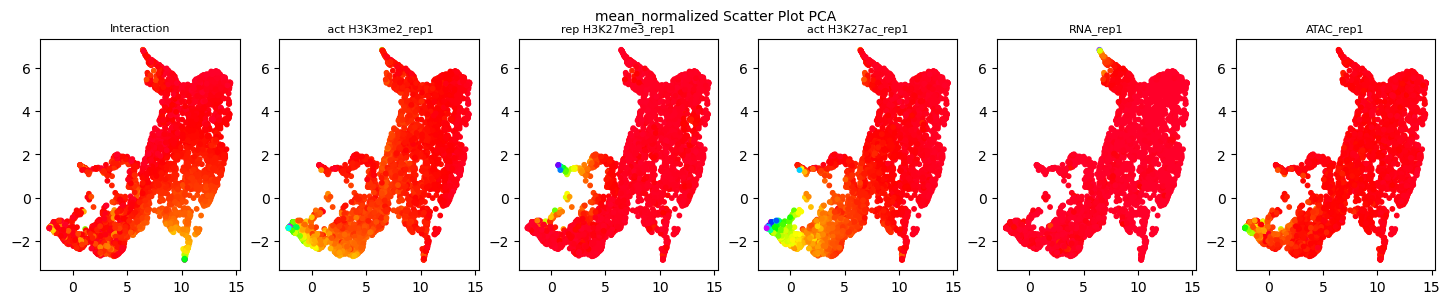

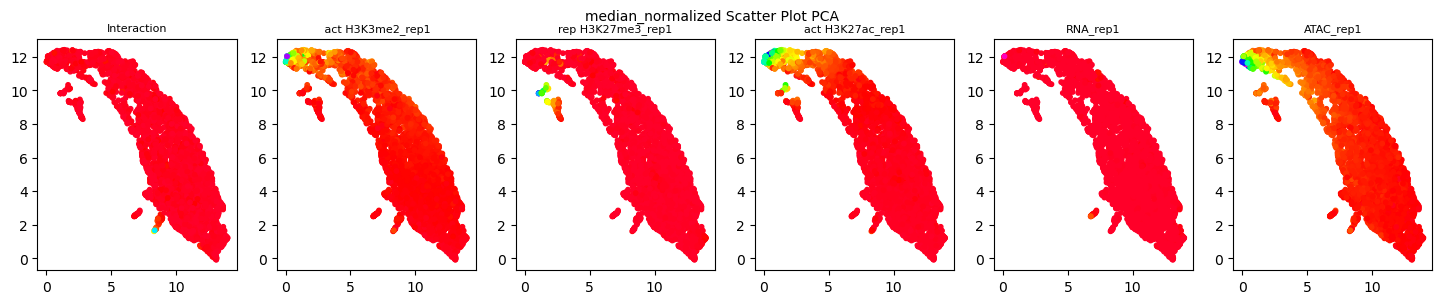

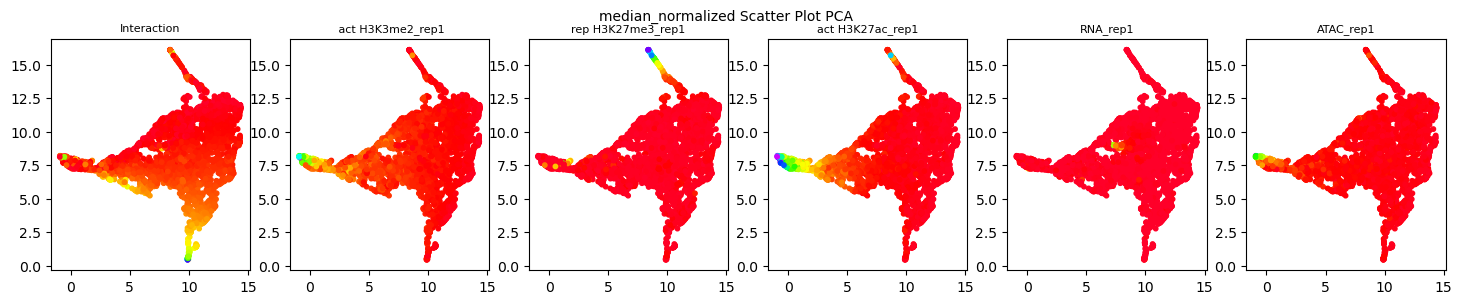

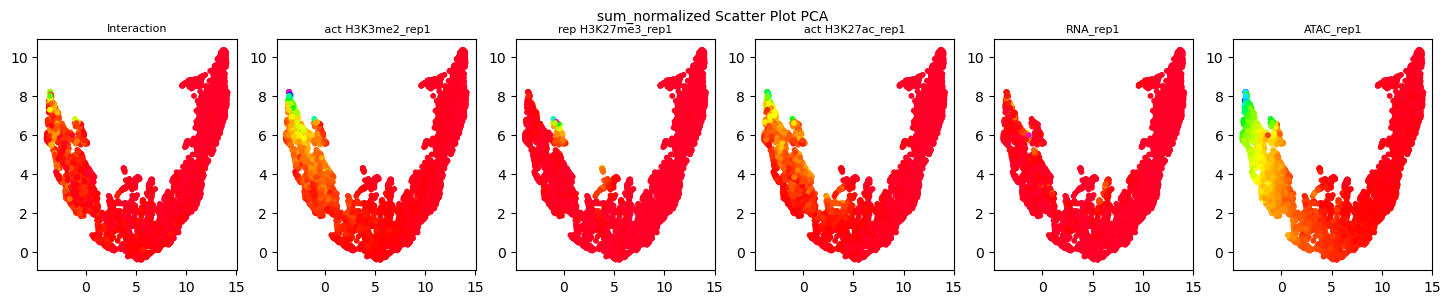

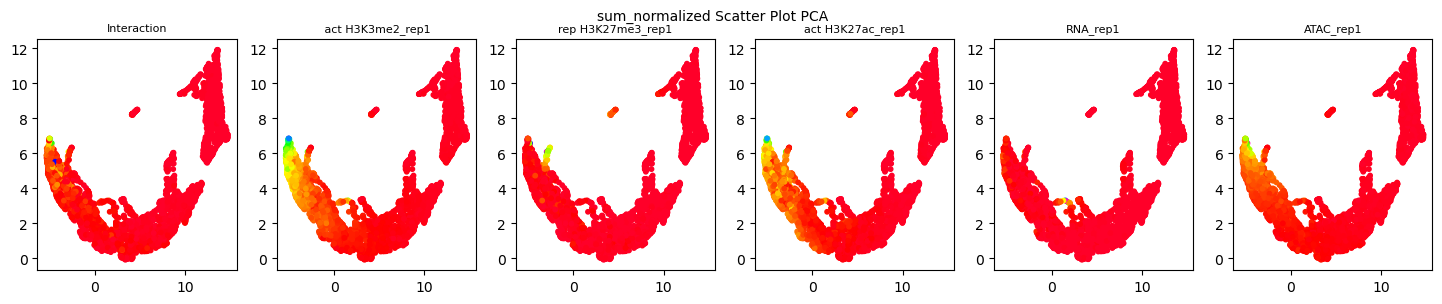

In [27]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotUMAP(different_communities_Pinna_E_12_5[i], title)
    plotUMAP(different_communities_Pinna_E_14_5[i], title)


In [33]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotPCA(different_communities_Pinna_E_14_5[i], title)

In [201]:
plotPCA(different_communities_Pinna_E_14_5[0] - different_communities_Pinna_E_12_5[0], title)

ValueError: operands could not be broadcast together with shapes (2349,13) (2457,13) 

In [37]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors()



In [17]:
def plotEmbedding(list_of_embeddings, list_of_subtitles, list_of_colorings, title_of_plot, fontsize=8):
    fig, axs = plt.subplots(1, len(list_of_subtitles), figsize=(3 * len(list_of_subtitles), 3))

    for i, (title, coloring) in enumerate(zip(list_of_subtitles, list_of_colorings)):
        # Plot the first version
        axs[i].scatter(list_of_embeddings[0], list_of_embeddings[1], c=coloring, cmap='gist_rainbow', s=10)  # Change the value of s to adjust the dot size
        axs[i].set_title(title, fontsize=fontsize)

    fig.suptitle(title_of_plot, fontsize=fontsize+2)
    plt.show()

In [27]:
import matplotlib.pyplot as plt

In [328]:
len(different_communities_Pinna_E_12_5[-1])

469

In [325]:
plt.figure(figsize=(15, 8))
plot_matrix = different_communities_Pinna_E_14_5[-1] - different_communities_Pinna_E_12_5[-1]
sorted_indices = np.argsort(plot_matrix[:, 1])
sorted_matrix = plot_matrix[sorted_indices]
plt.imshow(sorted_matrix, cmap='RdBu_r', interpolation='nearest', aspect='auto')
plt.title('Community Matrix')
plt.xlabel('Matrix Columns')
plt.ylabel('Community ID')
plt.colorbar()

# Add ticks per column with text in 45-degree angle
ticks = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
plt.xticks(range(len(ticks)), ticks, rotation=90, fontsize=8)



ValueError: operands could not be broadcast together with shapes (1962,13) (469,13) 

<Figure size 1500x800 with 0 Axes>

In [ ]:
plt.show()

In [ ]:
elements_per_community

array([ 55., 228., 161., ...,   1.,   1.,   1.])

In [ ]:
np.mean(matrix[community_id, :].tocsr().data)

0.018751868987494782

In [ ]:
matrix[community_id, :].tocsr().data

array([0.00911416, 0.02037817, 0.02676329])

In [ ]:
bw.chroms()

{'chr1': 195471971,
 'chr10': 130694993,
 'chr11': 122082543,
 'chr12': 120129022,
 'chr13': 120421639,
 'chr14': 124902244,
 'chr15': 104043685,
 'chr16': 98207768,
 'chr17': 94987271,
 'chr18': 90702639,
 'chr19': 61431566,
 'chr1_GL456210_random': 169725,
 'chr1_GL456211_random': 241735,
 'chr1_GL456212_random': 153618,
 'chr1_GL456213_random': 39340,
 'chr1_GL456221_random': 206961,
 'chr2': 182113224,
 'chr3': 160039680,
 'chr4': 156508116,
 'chr4_GL456216_random': 66673,
 'chr4_GL456350_random': 227966,
 'chr4_JH584292_random': 14945,
 'chr4_JH584293_random': 207968,
 'chr4_JH584294_random': 191905,
 'chr4_JH584295_random': 1976,
 'chr5': 151834684,
 'chr5_GL456354_random': 195993,
 'chr5_JH584296_random': 199368,
 'chr5_JH584297_random': 205776,
 'chr5_JH584298_random': 184189,
 'chr5_JH584299_random': 953012,
 'chr6': 149736546,
 'chr7': 145441459,
 'chr7_GL456219_random': 175968,
 'chr8': 129401213,
 'chr9': 124595110,
 'chrM': 16299,
 'chrUn_GL456239': 40056,
 'chrUn_GL456359

## Is the bait still in the same community between conditions?

### Compute the jaccard similarity between all communities

In [105]:
def jaccardSimiliarityCommunities(community_1, community_2, number_of_baits):
    intersection_communities_nodes = []
    intersection_communities_jaccard = np.zeros((len(community_1), len(community_2)))
    intersection_communities_bait_jaccard = np.zeros((len(community_1), len(community_2)))
    for i in range(len(community_1)):
        intersection_communities_nodes.append({})
        for j in range(len(community_2)):
            intersection = community_1[i].intersection(community_2[j])

            if len(intersection) > 0:
                intersection_communities_nodes[i][j] = intersection
                intersection_communities_jaccard[i, j] = len(intersection) / len(community_1[i].union(community_2[j]))
                bait_intersection = {x for x in intersection if x <= number_of_baits}
                bait_community_1 = {x for x in community_1[i] if x <= number_of_baits}
                bait_community_2 = {x for x in community_2[j] if x <= number_of_baits}
                intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_community_1.union(bait_community_2))

    return intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard

In [106]:
intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard = jaccardSimiliarityCommunities(partition_Pinna_E12_5, partition_Pinna_E14_5, sample_matrix_Pinna_E12_5.shape[0])

In [83]:
intersection_communities_nodes[1268]

{1246: {8146, 8147, 642455, 642467, 642579, 642580},
 1251: {641455},
 1252: {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8761,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  641958,
  641960,
  641961,
  642001,
  642002,
  642003,
  642013,
  642074,
  642075,
  642076,
  642077,
  642078,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642096,
  642198,
  642199,
  642309,
  642310,
  642351,
  642352,
  642353,
  642355,
  642356,
  642358,
  642359,
  642360,
  642361,
  642411,
  642413,
  642426,
  642436,
  642437,
  642549,
  642551,
  642552,
  642554,
  642555,
  642559,
  642560,
  642562,
  642602,
  642606,
  642646,
  642649,
  642650,
  642651,
  642653,
  642671,
  642672}}

In [107]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values = np.sort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)


Top 10 values per row:
[[1.         0.         0.         0.         0.        ]
 [0.28571429 0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   2 3638 1207 1219 1218]
 [   3 3638 1207 1219 1218]
 [   5 3638 1207 1219 1218]
 ...
 [3638 1193 1219 1218 1217]
 [3638 1193 1219 1218 1217]
 [3638 1193 1219 1218 1217]]


In [108]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values_communities = np.sort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices_communities = np.argsort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)

Top 10 values per row:
[[1.         0.         0.         0.         0.        ]
 [0.28571429 0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   2 3638 1207 1219 1218]
 [   3 3638 1207 1219 1218]
 [   5 3638 1207 1219 1218]
 ...
 [3638 1193 1219 1218 1217]
 [3638 1193 1219 1218 1217]
 [3638 1193 1219 1218 1217]]


In [109]:
top_10_indices[1268]

array([1375, 3638, 1208, 1220, 1219])

In [110]:
top_10_indices_communities[12]

array([  14, 3638, 1219, 1218, 1217])

In [55]:
top_10_values_communities[1268]

array([0.41145833, 0.02281369, 0.00581395, 0.        , 0.        ])

In [111]:
top_10_values[1268]

array([1., 0., 0., 0., 0.])

In [57]:
intersection_communities_nodes[1268]

[{8146, 8147, 642455, 642467, 642579, 642580},
 {641455},
 {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8761,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  641958,
  641960,
  641961,
  642001,
  642002,
  642003,
  642013,
  642074,
  642075,
  642076,
  642077,
  642078,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642096,
  642198,
  642199,
  642309,
  642310,
  642351,
  642352,
  642353,
  642355,
  642356,
  642358,
  642359,
  642360,
  642361,
  642411,
  642413,
  642426,
  642436,
  642437,
  642549,
  642551,
  642552,
  642554,
  642555,
  642559,
  642560,
  642562,
  642602,
  642606,
  642646,
  642649,
  642650,
  642651,
  642653,
  642671,
  642672}]

After the jaccard similarity sorting:
- Which clusters have the identical baits?
- Which baits are equal between clusters?
- Which baits changed the cluster?
- Which baits are exclusive in one sample? For example jaccard similarity of Hoxa2 cluster is 0.76 to the clostest one, 0.03 to the next, and to all other 0. Where are the missing 0.2? Ideas: Baits are exclusive in sample 1 xor sample 2.

- For equal: 
  - How did the histone / RNA changed between the conditions? 
    - per both sides of the interaction get the histone / RNA / ATAC data, with replicates for DESeq2 table
  - How did the interaction strength changed? (Binary contact number change / summed value change / mean change) per community

- Baits changed cluster:
  - How did the histone / RNA changed between the conditions? 
  - How did it changed at those contacts that were lost / gained? Identifiy the contacts responsible for the loss / gain within the community. Get for both ends of a gained / lost contact from both samples the Histone / RNA / ATAC data for Deseq2 table

- Exclusive in one sample:
  - How did the histone / RNA changed between the conditions at the locations of baits / OE? 

Can we identifiy patterns? 
- 


#### Plot the distribution of the jaccard index for baits

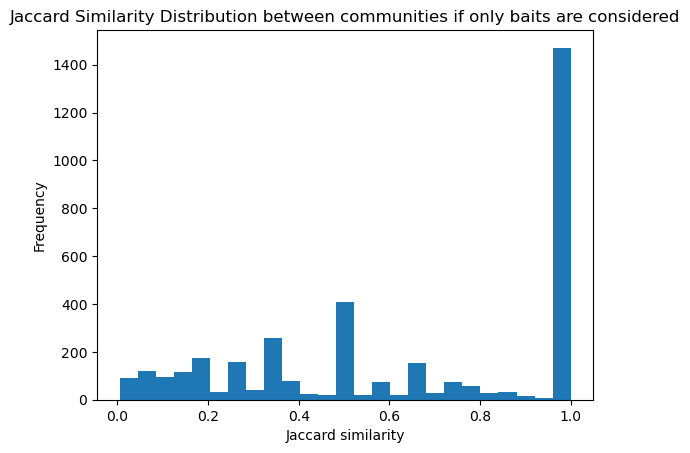

In [113]:
import numpy as np
import matplotlib.pyplot as plt

matrix = top_10_values
# Assuming your 2D matrix is named 'matrix'
non_zero_values = matrix[matrix != 0]

# Plot the histogram
plt.hist(non_zero_values, bins=25)
plt.xlabel('Jaccard similarity')
plt.ylabel('Frequency')
plt.title('Jaccard Similarity Distribution between communities if only baits are considered')
plt.show()

## Baits stay the same
- Do we see interaction strength change?

In [133]:
#### Take communities with a jaccard index of the baits of only 1.0
def findCommunitiesWithJaccardIndexOfOne(sorted_jaccard, partition_1, partition_2, number_of_baits, sample_matrices):
    
    count_table = []

    matching_indices = np.where(sorted_jaccard == 1.0)[0]
    for index in matching_indices:
        community_1 = partition_1[index]
        community_2 = partition_2[top_10_indices[index][0]]

        # get all baits
        community_1_baits = {x for x in community_1 if x <= number_of_baits}
        community_2_baits = {x for x in community_2 if x <= number_of_baits}
        baits = community_1_baits.union(community_2_baits)

        # if index == 3692:
        # ic(baits, index, community_1, community_2)

        # get for each bait from sample A and B the interactions
        for bait_index in baits:
            # matrix_sample_1[bait_index, :]
            # matrix_sample_2[bait_index, :]
            # ic(matrix_sample_1[bait_index, :], matrix_sample_2[bait_index, :])
            try:
                all_OE = np.unique(np.concatenate([intersection_matrices[bait_index, :].nonzero()[1], intersection_matrices[bait_index, :].nonzero()[1]]))
            except:
                ic(bait_index)
                ic(matrices_sample_1[0][bait_index, :])
                ic(matrices_sample_2[0][bait_index, :])
                break
            for interaction_index in all_OE:
                id = str(bait_index) + "_" + str(interaction_index)
                count_table_line = []
                count_table_line.append(id)
                for matrix in matrices_sample_1:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                for matrix in matrices_sample_2:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                count_table.append(count_table_line)
                # ic(interaction_index)
                # ic(matrix_sample_1[bait_index, interaction_index])

                # ic(matrix_sample_2[bait_index, interaction_index])
        # break
        # create a table to compare the interactions
    
    columns_ids = ['GeneID']
    for i in range(len(matrices_sample_1)):
        columns_ids.append("Sample1_" + str(i))
    for i in range(len(matrices_sample_2)):
        columns_ids.append("Sample2_" + str(i))
    count_table_df = pd.DataFrame(count_table, columns=columns_ids)
    count_table_df = count_table_df.set_index('GeneID')
    return count_table_df



In [135]:
count_table_df = findCommunitiesWithJaccardIndexOfOne(top_10_values, partition_Pinna_E12_5, partition_Pinna_E14_5, sample_matrix_Pinna_E12_5.shape[0], interaction_matrices_sample_Pinna_12_5[:2], interaction_matrices_sample_Pinna_14_5[:2])

ic| bait_index: 6


TypeError: 'hiCMatrix' object is not subscriptable

In [139]:
interaction_matrices_sample_Pinna_12_5[:2][0].matrix

<851636x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 134063 stored elements in Compressed Sparse Row format>

In [75]:
foo

,Sample1,Sample2,Sample3,Sample4
GeneID,,,,
21_2538,0,0,5,5
21_2539,0,0,5,5
21_2739,7,7,0,0
23_3032,8,8,0,0
23_3062,5,5,0,0
...,...,...,...,...
25104_825022,0,0,5,5
25104_825023,6,6,0,0
25104_825081,5,5,0,0


In [76]:
columnData = [['Sample1', 'E12.5', '1'], ['Sample2', 'E12.5', '2'], ['Sample3', 'E14.5', '1'], ['Sample4', 'E14.5', '2']]
columnData_df = pd.DataFrame(columnData, columns = ['Sample', 'Condition', 'Replicate'])
columnData_df = columnData_df.set_index('Sample')

In [66]:
columnData_df

,Condition,Replicate
Sample,,
Sample1,E12.5,1
Sample2,E12.5,2
Sample3,E14.5,1
Sample4,E14.5,2


In [70]:
foo


,Sample1,Sample2
GeneID,,
21_2538,0,5
21_2539,0,5
21_2739,7,0
23_3032,8,0
23_3062,5,0
...,...,...
25104_825022,0,5
25104_825023,6,0
25104_825081,5,0


In [68]:
r_dataframe_column

Condition,Replicate
...,...


In [77]:
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr

# Install and import DESeq2
if not importr("DESeq2", robject_translations={"format_pandas_data_frame": False}):
    robjects.r(f'install.packages("DESeq2")')
deseq2 = importr("DESeq2")

# Convert pandas DataFrame to R DataFrame
pandas2ri.activate()
r_dataframe = pandas2ri.DataFrame(foo)
r_dataframe_column = pandas2ri.DataFrame(columnData_df)


# Run DESeq2 analysis
design_formula = "~ Condition"  # Replace 'condition' with your actual condition variable
# dds = DESeq2.DESeqDataSetFromMatrix(countData=counts_r, colData=col_data_r, design=robjects.Formula(design_formula))
dds = deseq2.DESeqDataSetFromMatrix(countData=r_dataframe, colData=r_dataframe_column, design=robjects.Formula(design_formula))
dds = deseq2.DESeq(dds)

# Get differential expression results
results = deseq2.results(dds)

# Convert results to pandas DataFrame
results_dataframe = pandas2ri.ri2py(results)

# Print the results
print(results_dataframe)






  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


 



RRuntimeError: Error in estimateDispersionsFit(object, fitType = fitType, quiet = quiet) : 
  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


In [77]:
top_10_indices[index][0]

3599

In [69]:
matching_entries

array([[   1, 3599, 1195, 1207, 1206],
       [   2, 3599, 1195, 1207, 1206],
       [   3, 3599, 1195, 1207, 1206],
       ...,
       [3597, 3599, 1194, 1206, 1205],
       [3598, 1181, 1207, 1206, 1205],
       [3599, 1236, 1206, 1205, 1204]])

In [111]:
# Sort the values per highest row numbers
sorted_values = np.sort(top_10_values, axis=1)[:, ::-1]

# Keep the indices of the rows
sorted_indices = np.argsort(top_10_values, axis=1)[:, ::-1]

# Print the sorted values and indices
print("Sorted values per highest row numbers:")
print(sorted_values)
print("Indices of the rows:")
print(sorted_indices)


Sorted values per highest row numbers:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the rows:
[[0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]
 ...
 [0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]]


In [67]:
top_10_values[1295, :]

array([0.76923077, 0.04081633, 0.        , 0.        , 0.        ])

In [68]:
top_10_indices[1295, :]

array([1293, 1401, 3692, 1239, 1237])

In [62]:
top_10_indices[3692, :]

array([3509, 3508, 3692, 1224, 1235])

In [59]:
top_10_values.shape

(3884, 5)

In [39]:
print(communities_E12_5[1295].intersection(communities_E14_5[1293]))
print(len(communities_E12_5[1295].intersection(communities_E14_5[1293])))

print(len(communities_E12_5[1295]))
print(len(communities_E14_5[1293]))


{642560, 642562, 642074, 642075, 642076, 642077, 642078, 642079, 642080, 642081, 642082, 642083, 642084, 642085, 642086, 642087, 642088, 642089, 642602, 642606, 642096, 8761, 8765, 8766, 8767, 8768, 8769, 8771, 8773, 8774, 8775, 8776, 642646, 642649, 642650, 642651, 642653, 642671, 642672, 642198, 642199, 642309, 642310, 642351, 642352, 642353, 642355, 642356, 642358, 642359, 642360, 642361, 642411, 642413, 642426, 642436, 642437, 641958, 641960, 641961, 8133, 8137, 8138, 8139, 8140, 8142, 8143, 8144, 642001, 642002, 642003, 8145, 642013, 642549, 642551, 642552, 642554, 642555, 642559}
79
155
116


In [37]:
for i in range(len(communities_E12_5)):
    if 8767 in communities_E12_5[i]:
        print(i)
        break
for i in range(len(communities_E14_5)):
    if 8767 in communities_E14_5[i]:
        print(i)
        break

1295
1293


In [36]:
bait_list_Pinna_E12_5[8767]

Name    Hoxa2_1
Name: 8767, dtype: object

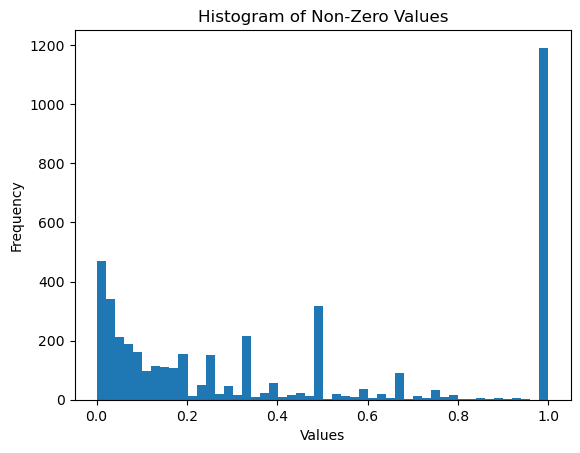

In [133]:
non_zero_values

array([0.02380952, 0.02380952, 0.02380952, ..., 1.        , 1.        ,
       1.        ])

In [119]:
import multiprocessing
distance_matrix = np.full((len(communities_E12_5), len(communities_E14_5)), -1)
subgraphs_E12_5 = []
subgraphs_E14_5 = []

def compute_distance(i, j):
    subgraph_E12_5 = G_Pinna_E12_5.subgraph(communities_E12_5[i])
    subgraph_E14_5 = G_Pinna_E14_5.subgraph(communities_E14_5[j])
    if nx.is_isomorphic(subgraph_E12_5, subgraph_E14_5):
        distance_matrix[i, j] = 0
    else:
        distance_matrix[i, j] = nx.optimize_graph_edit_distance(subgraph_E12_5, subgraph_E14_5)

pool = multiprocessing.Pool()
for i in range(len(communities_E12_5)):
    for j in range(len(communities_E14_5)):
        pool.apply_async(compute_distance, args=(i, j))

pool.close()
pool.join()


KeyboardInterrupt: 

: 

In [118]:
distance_matrix

array([[-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       ...,
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1]])

In [102]:
max(partition_Pinna_E12_5.values())

3887

In [103]:
len(community_E14_5)

3693

In [104]:
max(partition_Pinna_E14_5.values())

3691